## 0. Préparation (crée le fichier nettoyage.py automatiquement)

In [ ]:
%%writefile nettoyage.py
"""Prétraitement partagé par le notebook (entraînement) et l'API (prédiction).

Il est indispensable d'appliquer EXACTEMENT le même nettoyage à l'entraînement
et à la prédiction, sinon le modèle reçoit des textes qu'il n'a jamais vus.
"""
import re
import unicodedata

# Mots vides français + anglais. On GARDE volontairement les négations
# (pas, ne, jamais, rien, sans, non...) car elles changent le sens d'un avis :
# "pas bon" ne doit pas devenir "bon".
STOP_WORDS = set("""
le la les l un une des du de d et ou mais donc or ni car à a au aux en dans sur sous par pour avec chez
ce cet cette ces ca ça cela celui celle ceux celles je j tu il elle on nous vous ils elles me m te t se s
mon ma mes ton ta tes son sa ses notre nos votre vos leur leurs qui que qu quoi dont où y
est es sont suis etes êtes sommes etait était ete été etre être ai as avons avez ont avait avoir
the a an and or but of to in on at for with is are was were be been this that these those it its
i you he she we they me my your his her our their
""".split()) - {"pas", "ne", "non", "jamais", "rien", "sans", "plus"}

_URL = re.compile(r"(https?://\S+|www\.\S+)")
_NON_LETTRES = re.compile(r"[^a-zà-ÿœæ\s]")  # supprime ponctuation, chiffres, emojis...
_ESPACES = re.compile(r"\s+")


def nettoyer_texte(texte: str) -> str:
    """minuscules -> sans liens -> sans ponctuation/chiffres -> sans mots vides."""
    if not isinstance(texte, str):
        return ""
    t = texte.lower()
    t = _URL.sub(" ", t)
    t = t.replace("’", " ").replace("'", " ")  # "l'hôtel" -> "l hôtel"
    t = unicodedata.normalize("NFC", t)
    t = _NON_LETTRES.sub(" ", t)
    mots = [m for m in _ESPACES.split(t) if m and m not in STOP_WORDS and len(m) > 1]
    return " ".join(mots)

Writing nettoyage.py


**Donnees**

In [ ]:
import os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, f1_score)

from nettoyage import nettoyer_texte

SEED = 42
random.seed(SEED); np.random.seed(SEED)

In [ ]:
# ===================== CONFIGURATION (à adapter) =====================
CSV_PATH   = "Tweets.csv"   # votre fichier (Kaggle, Amazon Reviews, Yelp...)
COL_TEXTE  = "text"       # nom de la colonne contenant l'avis
COL_NOTE   = None         # colonne de la note en étoiles (1 à 5)... ou None si déjà étiqueté
COL_LABEL  = "airline_sentiment"  # colonne contenant déjà 'positif'/'negatif'/'neutre' (sinon None)
SEP        = ","          # séparateur du CSV
# =====================================================================

def note_vers_sentiment(n):
    # Mapping demandé : 1-2 = négatif, 3 = neutre, 4-5 = positif
    if n <= 2: return "negatif"
    if n == 3: return "neutre"
    return "positif"

def jeu_demo(n_par_classe=400):
    # Jeu ARTIFICIEL, juste pour tester le code. À remplacer par un vrai dataset.
    pos = ["excellent produit", "très satisfait de mon achat", "service rapide et efficace", "je recommande vivement",
           "qualité au top", "super expérience", "livraison rapide et produit conforme", "j'adore, parfait"]
    neg = ["produit décevant", "très mauvaise qualité", "livraison trop lente", "je ne recommande pas",
           "arrivé cassé, pas content", "service client nul", "une arnaque, ne jamais acheter", "complètement inutile"]
    neu = ["produit correct sans plus", "ni bon ni mauvais", "conforme à la description", "moyen, rien de spécial",
           "livraison dans les temps, produit standard", "ça fait le travail", "prix moyen pour une qualité moyenne", "acceptable"]
    liant = ["", "globalement, ", "franchement, ", "pour ce prix, ", "à noter : "]
    fin = ["", " voilà mon avis", " vu à ce prix", " en résumé"]
    lignes = []
    for lab, phrases in [("positif", pos), ("negatif", neg), ("neutre", neu)]:
        for _ in range(n_par_classe):
            # 15 % de bruit : un avis prend une phrase d'une autre classe
            src = phrases if random.random() > 0.15 else random.choice([pos, neg, neu])
            lignes.append({"texte": random.choice(liant) + random.choice(src) + random.choice(fin), "sentiment": lab})
    return pd.DataFrame(lignes).sample(frac=1, random_state=SEED).reset_index(drop=True)

if os.path.exists(CSV_PATH):
    df = pd.read_csv(CSV_PATH, sep=SEP)
    df = df.rename(columns={COL_TEXTE: "texte"})
    if COL_LABEL:
        df["sentiment"] = df[COL_LABEL].str.lower().str.strip()
        df["sentiment"] = df["sentiment"].replace({"positive": "positif", "negative": "negatif", "neutral": "neutre"})
    else:
        df["sentiment"] = df[COL_NOTE].astype(float).apply(note_vers_sentiment)
    df = df[["texte", "sentiment"]]
    DEMO = False
else:
    print("⚠️ Fichier introuvable : utilisation du jeu de DÉMONSTRATION artificiel.")
    df = jeu_demo()
    DEMO = True

print("Taille du jeu de données :", df.shape)
df.head()

Taille du jeu de données : (14640, 2)


,texte,sentiment
0,@VirginAmerica What @dhepburn said.,neutre
1,@VirginAmerica plus you've added commercials t...,positif
2,@VirginAmerica I didn't today... Must mean I n...,neutre
3,@VirginAmerica it's really aggressive to blast...,negatif
4,@VirginAmerica and it's a really big bad thing...,negatif


sentiment
negatif    9178
neutre     3099
positif    2363
Name: count, dtype: int64
sentiment
negatif    62.7 %
neutre     21.2 %
positif    16.1 %
Name: count, dtype: object


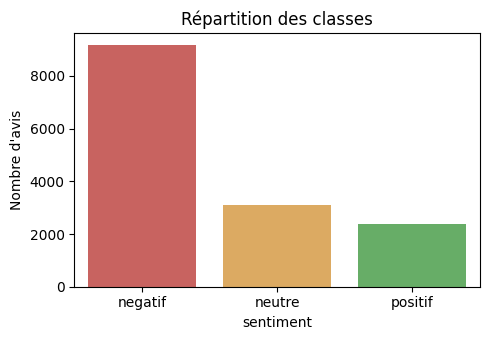

In [ ]:
repartition = df["sentiment"].value_counts()
print(repartition)
print((repartition / len(df) * 100).round(1).astype(str) + " %")

plt.figure(figsize=(5, 3.5))
sns.countplot(data=df, x="sentiment", order=["negatif", "neutre", "positif"],
              hue="sentiment", palette={"negatif": "#d9534f", "neutre": "#f0ad4e", "positif": "#5cb85c"}, legend=False)
plt.title("Répartition des classes"); plt.ylabel("Nombre d'avis"); plt.tight_layout(); plt.show()

**Commentaire (à rédiger avec vos chiffres)** : la classe *neutre* est-elle sous-représentée ?
Dans les datasets d'avis, les 3 étoiles sont souvent minoritaires. Un déséquilibre pousse les modèles à
ignorer la classe rare : on y répondra avec `class_weight='balanced'` et en comparant avec le **F1 macro**.

2. Pretraitement

In [ ]:
avant = len(df)
df = df.dropna(subset=["texte", "sentiment"])
df = df.drop_duplicates(subset="texte")
df["texte_propre"] = df["texte"].apply(nettoyer_texte)
df = df[df["texte_propre"].str.strip() != ""].reset_index(drop=True)
print(f"{avant} -> {len(df)} avis après suppression des doublons / textes vides")

# Exemple avant / après
for i in range(3):
    print("AVANT :", df.loc[i, "texte"])
    print("APRÈS :", df.loc[i, "texte_propre"], "\n")

14640 -> 14427 avis après suppression des doublons / textes vides
AVANT : @VirginAmerica What @dhepburn said.
APRÈS : virginamerica what dhepburn said 

AVANT : @VirginAmerica plus you've added commercials to the experience... tacky.
APRÈS : virginamerica plus ve added commercials experience tacky 

AVANT : @VirginAmerica I didn't today... Must mean I need to take another trip!
APRÈS : virginamerica didn today must mean need take another trip 



Le nettoyage (`nettoyage.py`) : minuscules, suppression des liens, de la ponctuation et des chiffres, puis des mots vides.
**Choix justifié** : on conserve les négations (*pas, ne, jamais, sans...*) car "pas bon" et "bon" ont des sens opposés.
Une lemmatisation (spaCy / NLTK) est optionnelle ; elle est omise ici pour garder le pipeline léger.

## 3. Découpage train / test (80 / 20)

In [ ]:
X = df["texte_propre"]
y = df["sentiment"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train :", len(X_train), "| Test :", len(X_test))
print("\nProportions train :\n", y_train.value_counts(normalize=True).round(3))
print("\nProportions test  :\n", y_test.value_counts(normalize=True).round(3))

Train : 11541 | Test : 2886

Proportions train :
 sentiment
negatif    0.629
neutre     0.212
positif    0.159
Name: proportion, dtype: float64

Proportions test  :
 sentiment
negatif    0.629
neutre     0.212
positif    0.159
Name: proportion, dtype: float64


## 4. Vectorisation TF-IDF

- **TF (Term Frequency)** : fréquence d'un mot dans *un* document. Plus un mot revient dans l'avis, plus il compte.
- **IDF (Inverse Document Frequency)** : `log(N / df)`. Un mot présent dans presque tous les avis ("produit") est peu informatif
  et reçoit un faible poids ; un mot rare mais discriminant ("décevant") reçoit un poids élevé.
- **TF-IDF = TF × IDF** : un mot est important s'il est fréquent dans l'avis **et** rare dans le corpus.

Le `TfidfVectorizer` est ajusté (`fit`) **uniquement sur le train**. Dans un `Pipeline`, c'est automatique :
`pipe.fit(X_train)` n'apprend le vocabulaire et l'IDF que sur le train, et `pipe.predict(X_test)` ne fait que `transform`.

In [ ]:
# Petite exploration de quelques paramètres TF-IDF (avec un SVM linéaire comme référence)
essais = [
    {"max_features": 5000,  "ngram_range": (1, 1), "min_df": 1},
    {"max_features": 20000, "ngram_range": (1, 2), "min_df": 1},
    {"max_features": 20000, "ngram_range": (1, 2), "min_df": 2},
]
for p in essais:
    pipe = Pipeline([("tfidf", TfidfVectorizer(**p)), ("clf", LinearSVC(class_weight="balanced"))])
    pipe.fit(X_train, y_train)
    f1 = f1_score(y_test, pipe.predict(X_test), average="macro")
    print(p, "-> F1 macro test = %.3f" % f1)

{'max_features': 5000, 'ngram_range': (1, 1), 'min_df': 1} -> F1 macro test = 0.726
{'max_features': 20000, 'ngram_range': (1, 2), 'min_df': 1} -> F1 macro test = 0.743
{'max_features': 20000, 'ngram_range': (1, 2), 'min_df': 2} -> F1 macro test = 0.742


## 5. Entraînement : Pipeline + GridSearchCV

| Algorithme | Hypothèses / hyperparamètres |
|---|---|
| **SVM** (`LinearSVC`) | noyau linéaire (adapté aux données TF-IDF, creuses et de grande dimension) ; `C` contrôle la marge : petit C = plus de régularisation |
| **Naïve Bayes** (`MultinomialNB`) | indépendance conditionnelle des mots sachant la classe ; `alpha` = lissage de Laplace |
| **Random Forest** | `n_estimators` (nombre d'arbres), `max_depth` (profondeur max) |

In [ ]:
tfidf_params = {"tfidf__ngram_range": [(1, 1), (1, 2)], "tfidf__min_df": [1, 2]}

config = {
    "SVM": (LinearSVC(class_weight="balanced", random_state=42),
            {"clf__C": [0.1, 1, 10]}),
    "Naive Bayes": (MultinomialNB(),
            {"clf__alpha": [0.1, 0.5, 1.0]}),
    "Random Forest": (RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=42),
            {"clf__n_estimators": [100, 200], "clf__max_depth": [None, 50]}),
}

meilleurs = {}
for nom, (clf, grille) in config.items():
    pipe = Pipeline([("tfidf", TfidfVectorizer(max_features=20000)), ("clf", clf)])
    gs = GridSearchCV(pipe, {**tfidf_params, **grille}, cv=5, scoring="f1_macro", n_jobs=-1)
    gs.fit(X_train, y_train)
    meilleurs[nom] = gs.best_estimator_
    print(f"{nom:14s} | F1 macro CV = {gs.best_score_:.3f} | {gs.best_params_}")

SVM            | F1 macro CV = 0.735 | {'clf__C': 0.1, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 1)}
Naive Bayes    | F1 macro CV = 0.669 | {'clf__alpha': 0.1, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)}
Random Forest  | F1 macro CV = 0.705 | {'clf__max_depth': 50, 'clf__n_estimators': 200, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2)}


## 6. Évaluation sur le jeu de test

In [ ]:
resultats, predictions = [], {}
for nom, modele in meilleurs.items():
    pred = modele.predict(X_test)
    predictions[nom] = pred
    p, r, f, _ = precision_recall_fscore_support(y_test, pred, average="macro", zero_division=0)
    resultats.append({"Modèle": nom, "Accuracy": accuracy_score(y_test, pred),
                      "Précision (macro)": p, "Rappel (macro)": r, "F1 (macro)": f})
    print("=" * 60); print(nom); print(classification_report(y_test, pred, zero_division=0))

tableau = pd.DataFrame(resultats).set_index("Modèle").round(3)
tableau

SVM
              precision    recall  f1-score   support

     negatif       0.86      0.88      0.87      1816
      neutre       0.65      0.59      0.62       612
     positif       0.74      0.75      0.74       458

    accuracy                           0.80      2886
   macro avg       0.75      0.74      0.75      2886
weighted avg       0.80      0.80      0.80      2886

Naive Bayes
              precision    recall  f1-score   support

     negatif       0.79      0.95      0.86      1816
      neutre       0.70      0.40      0.51       612
     positif       0.79      0.58      0.67       458

    accuracy                           0.78      2886
   macro avg       0.76      0.64      0.68      2886
weighted avg       0.77      0.78      0.76      2886

Random Forest
              precision    recall  f1-score   support

     negatif       0.86      0.83      0.85      1816
      neutre       0.56      0.63      0.59       612
     positif       0.69      0.67      0.68  

,Accuracy,Précision (macro),Rappel (macro),F1 (macro)
Modèle,,,,
SVM,0.801,0.750,0.742,0.745
Naive Bayes,0.777,0.759,0.644,0.679
Random Forest,0.763,0.704,0.709,0.706


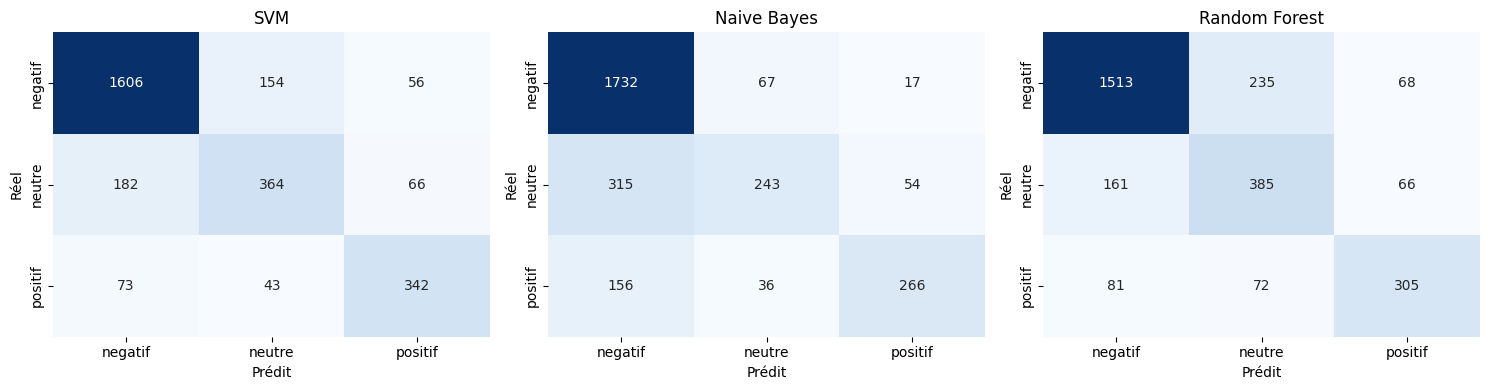

In [ ]:
classes = ["negatif", "neutre", "positif"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nom, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=classes)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax, cbar=False)
    ax.set_title(nom); ax.set_xlabel("Prédit"); ax.set_ylabel("Réel")
plt.tight_layout(); plt.show()

In [ ]:
# Analyse des erreurs : quelles phrases le meilleur modèle se trompe-t-il ?
nom_best = tableau["F1 (macro)"].idxmax()
print("Meilleur modèle (F1 macro sur le test) :", nom_best)
err = pd.DataFrame({"texte": X_test.values, "réel": y_test.values, "prédit": predictions[nom_best]})
err = err[err["réel"] != err["prédit"]]
print(len(err), "erreurs")
err.head(10)

Meilleur modèle (F1 macro sur le test) : SVM
574 erreurs


,texte,réel,prédit
4,united forgot intl flights out lax don go from...,positif,neutre
8,united all set figured out baggage office,neutre,negatif
10,jetblue have someone driving best get wheelcha...,neutre,negatif
12,united friendly efficient air attendants coach ua,negatif,positif
18,expiring united offer buy transfer united mile...,positif,neutre
23,usairways thanks hour layover too icing cake l...,positif,negatif
30,united melaniespring ll see what can do kn run...,positif,neutre
37,so smart makes angry mt jetblue ve partnered w...,positif,neutre
43,southwestair today going day can feel thank al...,neutre,positif
46,jetblue thank headed from lbc oak,neutre,positif


### Analyse (à rédiger dans le rapport)
- Quelle classe a le F1 le plus faible ? Sur des avis réels, c'est presque toujours **neutre** : un avis à 3 étoiles mélange des
  mots positifs et négatifs ("bien mais cher"), sans vocabulaire propre ; la frontière avec positif/négatif est floue.
- **SVM linéaire** : généralement le meilleur sur TF-IDF (données creuses, grande dimension).
- **Naïve Bayes** : très rapide, bon point de départ, mais l'hypothèse d'indépendance des mots est forte (ex. négations, bigrammes).
- **Random Forest** : souvent le moins adapté au texte (des milliers de colonnes creuses), plus lent et rarement meilleur.
- Justifiez votre choix **avec vos chiffres** (F1 macro, F1 de la classe neutre, temps d'entraînement).

## 7. Sauvegarde du meilleur modèle

In [ ]:
joblib.dump(meilleurs[nom_best], "modele_sentiment.joblib")
print("Modèle sauvegardé :", nom_best)

# Vérification : l'API appliquera nettoyer_texte() puis predict()
tests = ["Produit excellent, je le recommande !", "Très déçu, livraison nulle et pas de remboursement.",
         "Le colis est arrivé mardi, conforme à la description."]
m = joblib.load("modele_sentiment.joblib")
for t in tests:
    print(m.predict([nettoyer_texte(t)])[0], "<-", t)
if DEMO:
    print("\n⚠️ Modèle entraîné sur le jeu de démonstration : ne pas l'utiliser pour le rendu.")

Modèle sauvegardé : SVM
positif <- Produit excellent, je le recommande !
negatif <- Très déçu, livraison nulle et pas de remboursement.
negatif <- Le colis est arrivé mardi, conforme à la description.


## 8. Limites (à compléter dans le rapport)
- TF-IDF ignore l'ordre et le contexte des mots (ironie, sarcasme, négations lointaines).
- Les étiquettes issues des étoiles sont bruitées (un 3 étoiles peut être très positif).
- Vocabulaire dépendant du domaine du dataset (un modèle entraîné sur des hôtels généralise mal aux films).
- Pistes : lemmatisation, embeddings, modèles de type transformer (CamemBERT), plus de données neutres.